# Лабораторная работа 4 — методы оптимизации и стохастические процессы

**Тема ВКР:** «Исследование влияния качества и дрейфа данных на продуктовые метрики».  
**Автор:** Яковенко Арина.  
**Среда:** Google Colab, GPU Tesla T4.  

Измеряем, как выбор оптимизатора влияет на скорость обучения и качество бинарной классификации отзывов, а затем проверяем качество на позднем периоде и при стохастической порче текста. Метка «жалоба» соответствует рейтингу 1–2, «не жалоба» — 4–5; нейтральные отзывы исключены. Рейтинг **не подается модели**. Источник совпадает с лабораторными 1–2. Это прокси жалобы, а не проверенная разметка обращений поддержки.

## 1. Исследовательский обзор

| Первичная работа | Идея и предпосылка | Связь с экспериментом / предел переноса |
|---|---|---|
| Robbins & Monro (1951), [стохастическая аппроксимация](https://doi.org/10.1214/aoms/1177729586) | Обновления при шумной оценке градиента | Mini-batch дает шум; конечный бюджет не проверяет асимптотику |
| Sutskever et al. (2013), [momentum и инициализация](https://proceedings.mlr.press/v28/sutskever13.html) | Инерция ускоряет движение по устойчивому направлению | Momentum/Nesterov, общий старт по seed |
| Duchi et al. (2011), [AdaGrad](https://www.jmlr.org/papers/v12/duchi11a.html) | Координатный шаг для разреженных признаков | TF–IDF разрежен; сравниваем AdaGrad |
| Kingma & Ba (2015), [Adam](https://arxiv.org/abs/1412.6980) | Моменты градиента и адаптивный шаг | Базовый адаптивный метод |
| Loshchilov & Hutter (2019), [AdamW](https://arxiv.org/abs/1711.05101) | Отделенный weight decay | Проверяем регуляризацию при равном бюджете |
| Liu et al. (2020), [RAdam](https://arxiv.org/abs/1908.03265) | Коррекция ранней дисперсии шага | Сравниваем устойчивость первых эпох |
| Reddi et al. (2018), [On the Convergence of Adam and Beyond](https://openreview.net/forum?id=ryQu7f-RZ) | Контрпример сходимости Adam | Нельзя объявлять Adam универсально лучшим |
| Hardt et al. (2016), [Stability of SGD](https://arxiv.org/abs/1509.01240) | Связь числа шагов и обобщения | Раздельно измеряем train/validation/test |
| Wilson et al. (2017), [Marginal Value of Adaptive Methods](https://arxiv.org/abs/1705.08292) | Адаптивность не гарантирует обобщение | Нужен поздний тест |
| Keskar et al. (2017), [Large-Batch Training](https://arxiv.org/abs/1609.04836) | Размер batch меняет динамику | Sensitivity по batch size |
| Mandt et al. (2017), [SGD as Approximate Bayesian Inference](https://www.jmlr.org/papers/v18/17-214.html) | Стационарное распределение параметров при шуме | Интерпретация межseedового разброса с оговорками |
| Künsch (1989), [block bootstrap](https://doi.org/10.1214/aos/1176347265) | Блоки сохраняют локальную зависимость | Интервалы для упорядоченного по времени теста |
| Li & Liu (2022), [high-probability SGD](https://proceedings.mlr.press/v162/li22q.html) | Высоковероятностные оценки при тяжелых хвостах шума | Интервалы и клиппинг градиента мотивированы, но условия теоремы здесь не проверены |
| Beznosikov et al. (2023), [Markovian noise](https://papers.neurips.cc/paper_files/paper/2023/hash/8c3e38ce55a0fa44bc325bc6fdb7f4e5-Abstract-Conference.html) | Методы первого порядка при зависимом марковском шуме | Марковские серии порчи тестируют чувствительность входа, не саму теорему сходимости |
| McAuley et al. (2024), [Amazon Reviews 2023](https://arxiv.org/abs/2403.03952) | Большой поток отзывов с timestamp | Реальные временные срезы и риск смещения |

**Разрыв:** опубликованные сравнения оптимизаторов редко связывают разброс результатов по seed с операционной метрикой пропущенных негативных отзывов при временном сдвиге и порче входов. Здесь делаем это при одной архитектуре и одном наборе данных. Теоремы для выпуклых/i.i.d. задач не доказывают превосходства на конечном невыпуклом классификаторе.

In [1]:
%pip -q install 'huggingface_hub>=1.32,<2' pyarrow scikit-learn scipy pandas matplotlib seaborn

In [2]:
import os, re, json, time, math, random, hashlib, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import pyarrow.parquet as pq
import torch, torch.nn as nn
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score, brier_score_loss, confusion_matrix
from scipy.stats import t as student_t
from IPython.display import display

assert torch.cuda.is_available(), 'Выберите T4 GPU: Runtime → Change runtime type.'
GPU=torch.cuda.get_device_name(0)
assert 'T4' in GPU.upper(), f'Ожидалась Tesla T4, получена {GPU}'
torch.set_num_threads(2)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE='cuda'; OUT=Path('/content/lab4_results'); OUT.mkdir(exist_ok=True)
print('GPU:',GPU,'PyTorch:',torch.__version__)


GPU: Tesla T4 PyTorch: 2.11.0+cu130


## 2. Паспорт данных и карта случайности

Parquet загружается **непосредственно в Colab** с Hugging Face по той же фиксированной ревизии, что в лабораторных 1–2. После очистки выполняем глобальную дедупликацию текста и только затем временное разбиение 65/15/20 %. Train и validation балансируем подвыборкой для устойчивого обучения; поздний test сохраняет естественную долю классов. Поэтому итоговый test отражает реальную долю меток в выбранной выборке, но эта доля всё равно не равна распространенности реальных обращений в поддержку.

| Источник случайности | Фиксация / измерение |
|---|---|
| Подвыборка и порядок mini-batch | 5 seed, shuffle только train |
| Инициализация сети и dropout | общий seed и идентичный начальный state для всех методов внутри seed |
| CUDA и вычисления | deterministic cuDNN, T4; полная битовая повторяемость не обещается |
| Learning rate | одинаковая сетка из 2 значений на отдельном pilot seed; test закрыт |
| Время и качество данных | временной test, независимые и марковские серии пропусков слов |
| Оценка эффекта | t-интервалы по 5 seed и блочный bootstrap по времени |


In [3]:
REPO='McAuley-Lab/Amazon-Reviews-2023'
REV='749931181c9cdd70bfa6408d8fe8b4ddd6107248'
FILE='raw_review_All_Beauty/full-00000-of-00001.parquet'
path=hf_hub_download(REPO,FILE,repo_type='dataset',revision=REV)
sha=hashlib.sha256(Path(path).read_bytes()).hexdigest()
raw=pq.read_table(path,columns=['rating','title','text','timestamp','parent_asin']).to_pandas()
print('Источник:',REPO,'revision:',REV,'SHA256:',sha,'Строк:',len(raw))
print('Пропуски:'); display(raw.isna().sum().to_frame('n'))
print('Рейтинги:'); display(raw.rating.value_counts(dropna=False).sort_index().to_frame('n'))
raw=raw[raw.rating.isin([1,2,4,5])].copy()
raw['review']=(raw.title.fillna('')+' '+raw.text.fillna('')).str.replace(r'\s+',' ',regex=True).str.strip()
raw=raw[raw.review.str.len().ge(20)&raw.timestamp.notna()].copy()
raw['norm']=raw.review.str.casefold(); before=len(raw)
raw=raw.sort_values('timestamp').drop_duplicates('norm',keep='first').drop(columns='norm')
raw['y']=raw.rating.isin([1,2]).astype('int8')
raw=raw.sort_values('timestamp').reset_index(drop=True)
q65,q80=raw.timestamp.quantile([.65,.80]).tolist()
period={'train':raw[raw.timestamp<=q65], 'val':raw[(raw.timestamp>q65)&(raw.timestamp<=q80)], 'test':raw[raw.timestamp>q80]}
def balanced_sample(frame,n_per_class,seed):
    return pd.concat([frame[frame.y==i].sample(n=min(n_per_class,(frame.y==i).sum()),random_state=seed) for i in [0,1]]).sort_values('timestamp').reset_index(drop=True)
train=balanced_sample(period['train'],3000,17)
val=balanced_sample(period['val'],600,19)
test=period['test'].sample(n=min(2500,len(period['test'])),random_state=23).sort_values('timestamp').reset_index(drop=True)
print('Удалено дублей:',before-len(raw),'| границы:',pd.to_datetime([q65,q80],unit='ms'))
display(pd.DataFrame([{'split':k,'n':len(v),'negative_%':100*v.y.mean(),'median_words':v.review.str.split().str.len().median(),'start':pd.to_datetime(v.timestamp.min(),unit='ms'),'end':pd.to_datetime(v.timestamp.max(),unit='ms')} for k,v in [('train',train),('val',val),('test',test)]]))
assert train.timestamp.max()<val.timestamp.min()<test.timestamp.min()
assert not set(train.review.str.casefold())&set(test.review.str.casefold())


raw_review_All_Beauty/full-00000-of-0000(…): reconstructing file:   0%|          |  0.00B /  139MB            

raw_review_All_Beauty/full-00000-of-0000(…): downloading bytes:           |  0.00B            

Источник: McAuley-Lab/Amazon-Reviews-2023 revision: 749931181c9cdd70bfa6408d8fe8b4ddd6107248 SHA256: b40ae565f1073e0b4960e2f424fe0c82f3d270b7c4d00bc9272ddd6a8b7411d7 Строк: 701528
Пропуски:


,n
rating,0
title,0
text,0
timestamp,0
parent_asin,0


Рейтинги:


,n
rating,
1.0,102080
2.0,43034
3.0,56307
4.0,79381
5.0,420726


Удалено дублей: 18373 | границы: DatetimeIndex(['2020-09-12 18:03:33.925000', '2021-06-01 03:31:09.454000'], dtype='datetime64[ns]', freq=None)


,split,n,negative_%,median_words,start,end
0,train,6000,50.00,25.0,2003-12-29 13:24:40.000,2020-09-12 10:58:47.286
1,val,1200,50.00,24.0,2020-09-12 18:38:26.976,2021-06-01 01:15:53.592
2,test,2500,30.76,24.0,2021-06-01 04:37:18.515,2023-09-01 22:11:38.819


In [4]:
V=TfidfVectorizer(max_features=2500,ngram_range=(1,2),min_df=2,sublinear_tf=True,dtype=np.float32)
Xtr=V.fit_transform(train.review).toarray(); Xv=V.transform(val.review).toarray(); Xte=V.transform(test.review).toarray()
ytr=train.y.to_numpy(dtype=np.float32); yv=val.y.to_numpy(dtype=np.float32); yte=test.y.to_numpy(dtype=np.float32)
Xtr_g=torch.tensor(Xtr,device=DEVICE); Ytr_g=torch.tensor(ytr,device=DEVICE)
Xv_g=torch.tensor(Xv,device=DEVICE); Xte_g=torch.tensor(Xte,device=DEVICE)
print('Размер словаря:',len(V.vocabulary_),'| GPU memory:',round(torch.cuda.memory_allocated()/2**20,1),'MiB')


Размер словаря: 2500 | GPU memory: 94.0 MiB


## 3. Единый протокол сравнения восьми оптимизаторов

Архитектура: TF–IDF → Linear(2500,64) → ReLU → Dropout(0.15) → Linear(64,1). Функция потерь — BCEWithLogits. Все 8 методов получают 6 эпох, batch 256, одинаковые данные, начальные веса и порядок batch внутри seed, без scheduler и early stopping. Learning rate выбирается на **pilot seed 101** по macro-F1 validation после 3 эпох из двух заранее заданных значений; затем фиксируется. Такой pilot не является независимой оценкой качества. Порог классификации подбирается на validation отдельно для каждого seed. Test применяется однократно после выбора метода по validation.


In [5]:
SEEDS=[11,22,33,44,55]
METHODS=['SGD','Momentum','Nesterov','AdaGrad','RMSprop','Adam','AdamW','RAdam']
LR_GRID={'SGD':[.1,.03],'Momentum':[.05,.01],'Nesterov':[.05,.01],'AdaGrad':[.03,.01],'RMSprop':[.001,.0003],'Adam':[.001,.0003],'AdamW':[.001,.0003],'RAdam':[.001,.0003]}
WD=.01; BATCH=256; EPOCHS=6
def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
def network(linear=False):
    return (nn.Linear(Xtr.shape[1],1) if linear else nn.Sequential(nn.Linear(Xtr.shape[1],64),nn.ReLU(),nn.Dropout(.15),nn.Linear(64,1))).to(DEVICE)
def optim(name,params,lr,wd=WD):
    if name=='SGD': return torch.optim.SGD(params,lr=lr,weight_decay=wd)
    if name=='Momentum': return torch.optim.SGD(params,lr=lr,momentum=.9,weight_decay=wd)
    if name=='Nesterov': return torch.optim.SGD(params,lr=lr,momentum=.9,nesterov=True,weight_decay=wd)
    if name=='AdaGrad': return torch.optim.Adagrad(params,lr=lr,weight_decay=wd)
    if name=='RMSprop': return torch.optim.RMSprop(params,lr=lr,weight_decay=wd)
    if name=='Adam': return torch.optim.Adam(params,lr=lr,weight_decay=wd)
    if name=='AdamW': return torch.optim.AdamW(params,lr=lr,weight_decay=wd)
    if name=='RAdam': return torch.optim.RAdam(params,lr=lr,weight_decay=wd)
    raise KeyError(name)
def prob(model,x):
    model.eval()
    with torch.no_grad(): return torch.sigmoid(model(x).flatten()).cpu().numpy()
def scores(y,p,thr):
    h=(p>=thr).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,h,labels=[0,1]).ravel()
    return dict(macro_f1=f1_score(y,h,average='macro',zero_division=0),negative_recall=recall_score(y,h,zero_division=0),negative_precision=precision_score(y,h,zero_division=0),false_negative=int(fn),false_positive=int(fp),auroc=roc_auc_score(y,p),brier=brier_score_loss(y,p))
def threshold(y,p):
    grid=np.linspace(.2,.8,25)
    return float(max(grid,key=lambda t:(f1_score(y,p>=t,average='macro'),-abs(t-.5))))
def train_once(name,seed,lr,epochs=EPOCHS,batch=BATCH,wd=WD,linear=False,initial=None,record=False):
    set_seed(seed);model=network(linear)
    if initial is not None:model.load_state_dict(initial)
    opt=optim(name,model.parameters(),lr,wd); loss_fn=nn.BCEWithLogitsLoss()
    gen=torch.Generator().manual_seed(seed+734)
    trace=[]; start=time.perf_counter(); instability=False; grad_norms=[]
    for ep in range(epochs):
        model.train(); perm=torch.randperm(len(Xtr),generator=gen,device='cpu').to(DEVICE)
        losses=[]
        for ix in perm.split(batch):
            opt.zero_grad(set_to_none=True);logit=model(Xtr_g[ix]).flatten();loss=loss_fn(logit,Ytr_g[ix])
            if not torch.isfinite(loss):instability=True;break
            loss.backward();gn=torch.nn.utils.clip_grad_norm_(model.parameters(),5.0)
            grad_norms.append(float(gn));opt.step();losses.append(float(loss.detach()))
        if instability:break
        pv=prob(model,Xv_g); th=threshold(yv,pv)
        trace.append({'epoch':ep+1,'train_loss':np.mean(losses),'val_macro_f1':scores(yv,pv,th)['macro_f1'],'grad_norm':np.mean(grad_norms[-math.ceil(len(Xtr)/batch):])})
    elapsed=time.perf_counter()-start
    if instability:return {'unstable':True,'seconds':elapsed,'trace':trace}
    pv=prob(model,Xv_g);th=threshold(yv,pv)
    return {'unstable':False,'seconds':elapsed,'threshold':th,'val':scores(yv,pv,th),'trace':trace,'model':model,'grad_mean':np.mean(grad_norms),'grad_sd':np.std(grad_norms)}
set_seed(101);base=network();INIT={k:v.clone() for k,v in base.state_dict().items()};del base
pilot=[]
for m in METHODS:
    for lr in LR_GRID[m]:
        z=train_once(m,101,lr,epochs=3,initial=INIT)
        pilot.append({'method':m,'lr':lr,'val_macro_f1':z.get('val',{}).get('macro_f1',-1),'seconds':z['seconds'],'unstable':z['unstable']})
pilot_df=pd.DataFrame(pilot);best_lr={m:float(pilot_df[pilot_df.method==m].sort_values(['val_macro_f1','seconds'],ascending=[False,True]).iloc[0].lr) for m in METHODS}
display(pilot_df);print('Fixed LR:',best_lr)


,method,lr,val_macro_f1,seconds,unstable
0,SGD,0.1000,0.338865,0.977902,False
1,SGD,0.0300,0.333333,0.287454,False
2,Momentum,0.0500,0.709123,0.295940,False
3,Momentum,0.0100,0.622266,0.290081,False
4,Nesterov,0.0500,0.781765,0.284185,False
5,Nesterov,0.0100,0.595355,0.281189,False
6,AdaGrad,0.0300,0.898329,0.391602,False
7,AdaGrad,0.0100,0.886665,0.303349,False
8,RMSprop,0.0010,0.889646,0.303830,False
9,RMSprop,0.0003,0.881658,0.316126,False


Fixed LR: {'SGD': 0.1, 'Momentum': 0.05, 'Nesterov': 0.05, 'AdaGrad': 0.03, 'RMSprop': 0.001, 'Adam': 0.001, 'AdamW': 0.001, 'RAdam': 0.0003}


In [6]:
runs=[]; curves=[]; trained={}; unstable_log=[]
for seed in SEEDS:
    set_seed(seed);initial={k:v.clone() for k,v in network().state_dict().items()}
    for m in METHODS:
        z=train_once(m,seed,best_lr[m],initial=initial)
        row={'method':m,'seed':seed,'lr':best_lr[m],'seconds':z['seconds'],'unstable':z['unstable']}
        if z['unstable']:
            unstable_log.append(row);runs.append(row);continue
        row.update({f'val_{k}':v for k,v in z['val'].items()});row.update({'threshold':z['threshold'],'grad_mean':z['grad_mean'],'grad_sd':z['grad_sd']})
        runs.append(row);trained[(m,seed)]=z['model']
        curves += [{'method':m,'seed':seed,**x} for x in z['trace']]
    print('seed',seed,'complete')
runs_df=pd.DataFrame(runs);curves_df=pd.DataFrame(curves)
assert len(runs_df)==40 and runs_df.seed.nunique()==5
display(runs_df.groupby('method').agg(val_f1=('val_macro_f1','mean'),sd=('val_macro_f1','std'),sec=('seconds','mean'),unstable=('unstable','sum')).sort_values('val_f1',ascending=False))


seed 11 complete
seed 22 complete
seed 33 complete
seed 44 complete
seed 55 complete


,val_f1,sd,sec,unstable
method,,,,
AdamW,0.911390,0.000674,0.611840,0
AdaGrad,0.899791,0.002357,0.617832,0
RMSprop,0.890132,0.001448,0.623182,0
Adam,0.887120,0.002823,0.617674,0
Nesterov,0.857942,0.028065,0.578825,0
Momentum,0.839109,0.030509,0.567377,0
SGD,0.744645,0.027771,0.567925,0
RAdam,0.601409,0.252514,0.609008,0


## 4. Выбор, интервалы и поздний тест

До просмотра test правило выбора: исключить методы с расходимостью; ранжировать по среднему validation macro-F1 (70 %), межseedовой стабильности (20 %) и времени (10 %). Это рабочее правило выбора, а не статистическое доказательство превосходства. Для каждого метода приводим 95 % t-интервал по 5 seed; он описывает вариацию запусков при данном split, не неопределенность нового распределения данных.

Validation winner: AdamW


,f1,sd,sec,unstable,ci_lo,ci_hi,score
method,,,,,,,
AdamW,0.911390,0.000674,0.611840,0,0.910553,0.912226,0.9500
AdaGrad,0.899791,0.002357,0.617832,0,0.896863,0.902718,0.7875
RMSprop,0.890132,0.001448,0.623182,0,0.888334,0.891930,0.7125
Adam,0.887120,0.002823,0.617674,0,0.883615,0.890625,0.6000
Nesterov,0.857942,0.028065,0.578825,0,0.823095,0.892789,0.5000
Momentum,0.839109,0.030509,0.567377,0,0.801227,0.876992,0.4125
SGD,0.744645,0.027771,0.567925,0,0.710163,0.779128,0.3625
RAdam,0.601409,0.252514,0.609008,0,0.287871,0.914947,0.1750


,test_f1,test_f1_sd,recall,missed,auroc,brier,ci_lo,ci_hi
method,,,,,,,,
AdaGrad,0.881231,0.006679,0.916515,64.2,0.963925,0.116573,0.872938,0.889524
AdamW,0.880391,0.007255,0.942783,44.0,0.968031,0.086851,0.871382,0.889399
RMSprop,0.875325,0.019163,0.897269,79.0,0.961146,0.149005,0.851531,0.899120
Adam,0.858107,0.016406,0.933680,51.0,0.959528,0.179891,0.837735,0.878478
Nesterov,0.813276,0.051912,0.932120,52.2,0.952777,0.236719,0.748818,0.877733
Momentum,0.796797,0.067060,0.922237,59.8,0.952652,0.237566,0.713531,0.880063
SGD,0.721667,0.035636,0.738622,201.0,0.868347,0.248710,0.677418,0.765915
RAdam,0.611566,0.211105,0.514434,373.4,0.933742,0.247033,0.349444,0.873687


Winner test interval: (np.float64(0.8713823484014767), np.float64(0.8893993923163568))


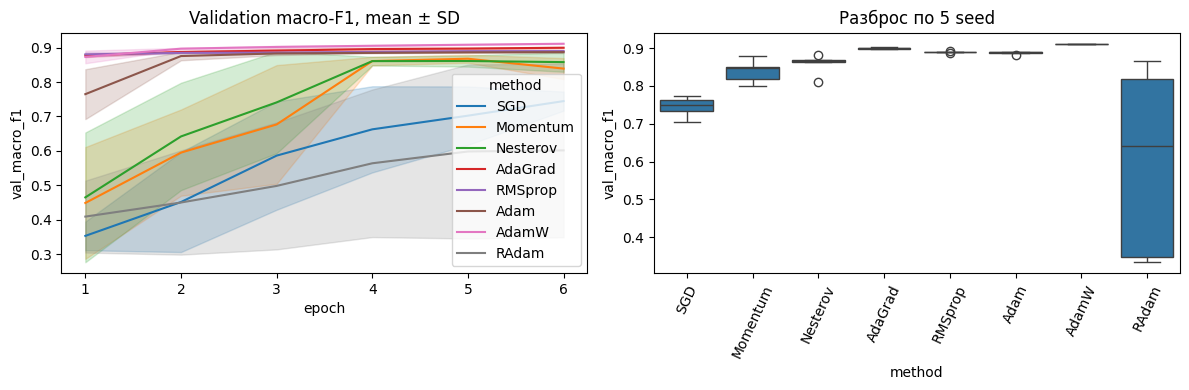

In [7]:
def ci(x):
    a=np.asarray(x,dtype=float);a=a[np.isfinite(a)]
    if len(a)<2:return (np.nan,np.nan)
    h=student_t.ppf(.975,len(a)-1)*a.std(ddof=1)/np.sqrt(len(a));return (a.mean()-h,a.mean()+h)
agg=runs_df.groupby('method').agg(f1=('val_macro_f1','mean'),sd=('val_macro_f1','std'),sec=('seconds','mean'),unstable=('unstable','sum'))
agg['ci_lo']=[ci(runs_df.loc[runs_df.method==m,'val_macro_f1'])[0] for m in agg.index]
agg['ci_hi']=[ci(runs_df.loc[runs_df.method==m,'val_macro_f1'])[1] for m in agg.index]
agg['score']=.7*agg.f1.rank(pct=True)+.2*(-agg.sd).rank(pct=True)+.1*(-agg.sec).rank(pct=True)
agg.loc[agg.unstable.gt(0),'score']=-np.inf
winner=agg.score.idxmax();print('Validation winner:',winner);display(agg.sort_values('score',ascending=False))
test_rows=[];predictions={}
for (m,s),model in trained.items():
    p=prob(model,Xte_g);predictions[(m,s)]=p
    th=float(runs_df[(runs_df.method==m)&(runs_df.seed==s)].threshold.iloc[0])
    test_rows.append({'method':m,'seed':s,'threshold':th,**scores(yte,p,th)})
test_df=pd.DataFrame(test_rows)
test_summary=test_df.groupby('method').agg(test_f1=('macro_f1','mean'),test_f1_sd=('macro_f1','std'),recall=('negative_recall','mean'),missed=('false_negative','mean'),auroc=('auroc','mean'),brier=('brier','mean'))
test_summary['ci_lo']=[ci(test_df.loc[test_df.method==m,'macro_f1'])[0] for m in test_summary.index]
test_summary['ci_hi']=[ci(test_df.loc[test_df.method==m,'macro_f1'])[1] for m in test_summary.index]
display(test_summary.sort_values('test_f1',ascending=False))
print('Winner test interval:',ci(test_df[test_df.method==winner].macro_f1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.lineplot(data=curves_df,x='epoch',y='val_macro_f1',hue='method',ax=ax[0],errorbar='sd');ax[0].set_title('Validation macro-F1, mean ± SD')
sns.boxplot(data=runs_df,x='method',y='val_macro_f1',ax=ax[1]);ax[1].tick_params(axis='x',rotation=65);ax[1].set_title('Разброс по 5 seed')
fig.tight_layout();fig.savefig(OUT/'optimizer_comparison.png',dpi=160);plt.show()


## 5. Перенос в текстовую ветвь лабораторной 2

В лабораторной 2 текстовая ветвь основана на TF–IDF и линейной модели. Здесь воспроизводим эту **текстовую абляцию** как один `Linear` слой в PyTorch на том же типе входа и бинарной метке, сравнивая выбранный оптимизатор с AdamW. Это проверка переноса в задачу мониторинга жалоб, но не переобучение полной мультимодальной модели: изображения и числовые признаки отсутствуют. При совпадении выбора с AdamW контроль — SGD с Momentum.

In [8]:
control='AdamW' if winner!='AdamW' else 'Momentum'
transfer=[]
for seed in SEEDS:
    set_seed(seed);init={k:v.clone() for k,v in network(linear=True).state_dict().items()}
    for m in [winner,control]:
        z=train_once(m,seed,best_lr[m],epochs=6,linear=True,initial=init)
        if z['unstable']:transfer.append({'method':m,'seed':seed,'unstable':True});continue
        p=prob(z['model'],Xte_g)
        transfer.append({'method':m,'seed':seed,'unstable':False,'val_f1':z['val']['macro_f1'],'test_f1':scores(yte,p,z['threshold'])['macro_f1'],'test_recall':scores(yte,p,z['threshold'])['negative_recall'],'seconds':z['seconds']})
transfer_df=pd.DataFrame(transfer);display(transfer_df.groupby('method').agg(val_f1=('val_f1','mean'),test_f1=('test_f1','mean'),recall=('test_recall','mean'),sec=('seconds','mean')))
paired=transfer_df.pivot(index='seed',columns='method',values='test_f1')
print('Paired difference',winner,'minus',control,'test F1:',paired[winner].mean()-paired[control].mean(),'95% CI:',ci(paired[winner]-paired[control]))


,val_f1,test_f1,recall,sec
method,,,,
AdamW,0.886228,0.861962,0.921977,0.546488
Momentum,0.875504,0.847987,0.928479,0.528507


Paired difference AdamW minus Momentum test F1: 0.013975314307866582 95% CI: (np.float64(-0.004357634396237207), np.float64(0.032308263011970324))


## 6. Градиентный шум, чувствительность и стохастические сценарии

Оценка шума: на одной и той же точке параметров считаем градиенты 20 независимых mini-batch и сравниваем квадратное отклонение от их среднего с квадратом средней нормы. Это эмпирическая оценка, зависящая от batch и точки обучения. Анализ чувствительности меняет LR × 0.5/1/2, batch 128/256/512 и weight decay 0/0.01/0.05 на отдельном seed 77. Для late test используем два сценария: независимое выпадение слов с вероятностью 0.15 и марковские серии (P(bad→bad)=0.85, P(good→bad)=0.025). Сценарии синтетические и не заменяют реальный поздний тест.

In [9]:
model=trained[(winner,SEEDS[0])];model.train();rng=np.random.default_rng(900)
gvec=[]
for _ in range(20):
    ix=torch.tensor(rng.choice(len(Xtr),size=128,replace=False),device=DEVICE)
    model.zero_grad(set_to_none=True);loss=nn.BCEWithLogitsLoss()(model(Xtr_g[ix]).flatten(),Ytr_g[ix]);loss.backward()
    gvec.append(torch.cat([p.grad.flatten().detach() for p in model.parameters()]).cpu().numpy())
G=np.stack(gvec);noise=float(np.mean(np.sum((G-G.mean(0))**2,axis=1)));signal=float(np.sum(G.mean(0)**2))
print('gradient noise/signal:',noise/max(signal,1e-12),'noise:',noise,'signal:',signal)
sense=[]
for label,kw in [('lr_half',{'lr':best_lr[winner]*.5}),('lr_base',{'lr':best_lr[winner]}),('lr_double',{'lr':best_lr[winner]*2}),('batch128',{'batch':128}),('batch512',{'batch':512}),('wd0',{'wd':0}),('wd005',{'wd':.05})]:
    z=train_once(winner,77,kw.get('lr',best_lr[winner]),batch=kw.get('batch',256),wd=kw.get('wd',WD))
    sense.append({'scenario':label,'val_f1':z.get('val',{}).get('macro_f1',np.nan),'seconds':z['seconds'],'unstable':z['unstable']})
sense_df=pd.DataFrame(sense);display(sense_df)


gradient noise/signal: 0.37478895958587827 noise: 0.0038956627249717712 signal: 0.010394283570349216


,scenario,val_f1,seconds,unstable
0,lr_half,0.902363,0.628675,False
1,lr_base,0.911537,0.617206,False
2,lr_double,0.919838,0.597801,False
3,batch128,0.919838,0.889419,False
4,batch512,0.900694,0.454174,False
5,wd0,0.911537,0.588439,False
6,wd005,0.911537,0.655591,False


,f1,recall,missed
scenario,,,
clean,0.880391,0.942783,44.0
iid_word_loss,0.866077,0.923537,58.8
markov_burst,0.869184,0.932900,51.6


Markov bad fraction: 0.1396


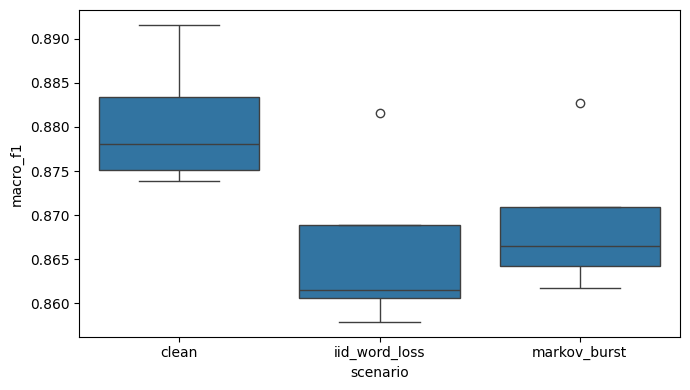

In [10]:
def drop_words(text,p,rng):
    words=text.split();kept=[w for w in words if rng.random()>p]
    return ' '.join(kept) if kept else (words[0] if words else '')
rng=np.random.default_rng(2026)
iid=[drop_words(s,.15,rng) for s in test.review]
bad=False;mark=[];bad_flags=[]
for s in test.review:
    bad=(rng.random()<(.85 if bad else .025));bad_flags.append(bad)
    mark.append(drop_words(s,.65 if bad else .0,rng))
scenario=[]
for name,texts in [('clean',test.review.tolist()),('iid_word_loss',iid),('markov_burst',mark)]:
    x=torch.tensor(V.transform(texts).toarray(),device=DEVICE)
    for seed in SEEDS:
        p=prob(trained[(winner,seed)],x);th=float(runs_df[(runs_df.method==winner)&(runs_df.seed==seed)].threshold.iloc[0])
        scenario.append({'scenario':name,'seed':seed,**scores(yte,p,th)})
scenario_df=pd.DataFrame(scenario)
display(scenario_df.groupby('scenario').agg(f1=('macro_f1','mean'),recall=('negative_recall','mean'),missed=('false_negative','mean')))
print('Markov bad fraction:',np.mean(bad_flags))
fig,ax=plt.subplots(figsize=(7,4));sns.boxplot(data=scenario_df,x='scenario',y='macro_f1',ax=ax);fig.tight_layout();fig.savefig(OUT/'stochastic_scenarios.png',dpi=160);plt.show()


## 7. Статистический протокол и ограничения

Пять seed измеряют вариацию обучения. Для разницы clean–Markov строим парный t-интервал по seed. Чтобы учесть локальную временную зависимость, дополнительно применяем moving-block bootstrap длиной 50 отзывов для test macro-F1 выбранной модели (первый seed, 500 повторов). Случайная подвыборка test и текстовая дедупликация ограничивают интерпретацию. Зависимость между отзывами одного товара и пользователя полностью не устраняется; `parent_asin` можно использовать для дополнительной кластерной оценки. Метки, полученные из рейтинга, содержат label noise: негативный текст может сопровождать высокий рейтинг и наоборот. Продуктовые величины — число пропущенных негативных отзывов на данном test, а не измеренные SLA или деньги.

In [11]:
wide=scenario_df.pivot(index='seed',columns='scenario',values='macro_f1')
print('Paired clean - Markov F1:',(wide['clean']-wide['markov_burst']).mean(),'95% CI:',ci(wide['clean']-wide['markov_burst']))
seed=SEEDS[0];p=predictions[(winner,seed)];th=float(runs_df[(runs_df.method==winner)&(runs_df.seed==seed)].threshold.iloc[0])
B=500;L=50;N=len(yte);rng=np.random.default_rng(812)
boots=[]
for _ in range(B):
    starts=rng.integers(0,N-L+1,size=math.ceil(N/L));ix=np.concatenate([np.arange(s,s+L) for s in starts])[:N]
    boots.append(f1_score(yte[ix],p[ix]>=th,average='macro',zero_division=0))
print('Moving-block bootstrap F1, 95% percentile CI:',np.quantile(boots,[.025,.975]))
print('Unstable runs:',unstable_log)
for name,obj in [('pilot',pilot_df),('runs',runs_df),('curves',curves_df),('validation_summary',agg.reset_index()),('test',test_df),('test_summary',test_summary.reset_index()),('transfer',transfer_df),('sensitivity',sense_df),('scenarios',scenario_df)]:obj.to_csv(OUT/f'{name}.csv',index=False)
manifest={'dataset':REPO,'revision':REV,'sha256':sha,'gpu':GPU,'seeds':SEEDS,'lr_grid':LR_GRID,'chosen_lr':best_lr,'winner':winner,'control':control,'budget':{'pilot_epochs':3,'main_epochs':EPOCHS,'batch':BATCH,'weight_decay':WD},'unstable_runs':unstable_log,'gradient_noise_ratio':noise/max(signal,1e-12)}
(OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print('Saved artifacts:',*[p.name for p in OUT.iterdir()],sep='\n')


Paired clean - Markov F1: 0.011207092179776067 95% CI: (np.float64(0.009456114283145184), np.float64(0.01295807007640695))
Moving-block bootstrap F1, 95% percentile CI: [0.85826287 0.88955722]
Unstable runs: []
Saved artifacts:
pilot.csv
validation_summary.csv
curves.csv
test_summary.csv
test.csv
scenarios.csv
sensitivity.csv
runs.csv
stochastic_scenarios.png
manifest.json
transfer.csv
optimizer_comparison.png


## 8. Вывод для ВКР

При одинаковой архитектуре и бюджете **AdamW** занял первое место по заранее заданному валидационному правилу: macro-F1 **0,9114**, 95% t-интервал по пяти seed **[0,9106; 0,9122]**, среднее время обучения **0,612 с**. На позднем test его macro-F1 составил **0,8804** [0,8714; 0,8894], recall негативных отзывов — **0,9428**, в среднем пропущено **44 из 2500** отзывов. AdaGrad дал близкий и немного более высокий test F1 (0,8812), однако выбирать его по test задним числом нельзя.

В текстовой линейной ветви задачи лабораторной 2 AdamW превысил Momentum на **0,0140 F1**, но 95% интервал парной разницы **[−0,0044; 0,0323]** включает ноль. Перенос выигрыша не доказан. Независимая потеря 15% слов снизила F1 до **0,8661** и увеличила число пропущенных негативных отзывов до **58,8**; марковские серии порчи дали F1 **0,8692** и **51,6** пропуска.

Таким образом, выбор оптимизатора влияет на скорость сходимости и качество, а ухудшение входного текста — на продуктовый прокси нагрузки поддержки. Пять seed и один временной split не доказывают универсального превосходства метода. Денежный эффект не оценивался без цены ошибки и реальной распространённости жалоб.